# Tutorial de geração, análise e extração de patches em imagens CBERS-4A

## Apresentação

Este notebook foi desenvolvido como um tutorial introdutório para pessoas que estão começando a aprender a manipular imagens de sensoriamento remoto utilizando Python no Google Colab.

O objetivo é apresentar, passo a passo, os procedimentos de caracterização de imagens, geração de patches com diferentes dimensões, análise de pixels NoData e preparação de amostras para projetos de classificação de imagens.

O tutorial também apresenta a utilização do CVAT para anotação de imagens, geração de máscaras e extração de amostras individuais.

### Antes de começar

**1. Prepare seu Google Drive.**

Na raiz de Meu Drive, crie uma pasta chamada `CBERS4A`.

**2. Adicione a imagem de entrada.**

Coloque a imagem GeoTIFF dentro dessa pasta, utilizando o nome `Area1.tif`.

O caminho esperado pelo código será:

`/content/drive/MyDrive/CBERS4A/Area1.tif`

Caso utilize uma imagem com outro nome, será necessário alterar esse caminho no código.

**3. Conecte o Google Drive ao Colab.**

Execute a célula de conexão ao Google Drive e autorize o acesso à sua conta.

**4. Organize as anotações do CVAT.**

Na etapa de importação das anotações, será necessário criar a pasta `CBERS4A/CVAT_anotacoes` e inserir nela o arquivo ZIP exportado do CVAT.

As demais pastas de saída serão criadas automaticamente pelas respectivas etapas do notebook.

**5. Execute as etapas na sequência apresentada.**

Algumas células dependem de variáveis e arquivos produzidos anteriormente. Por isso, recomenda-se acompanhar o tutorial desde o início.

### Observação

O notebook utiliza uma imagem CBERS-4A como exemplo. As dimensões dos patches e outros parâmetros podem ser adaptados às características e aos objetivos de diferentes projetos.

# Parte 1 - Análise das características da imagem e das resoluções

### 1- Instalar/importar a biblioteca Rasterio

In [ ]:
!pip install rasterio

### 2- Instalar bibliotecas:
rasterio → abre e manipula GeoTIFF.
numpy → permite trabalhar matematicamente com os pixels.
matplotlib.pyplot → permite mostrar as imagens e gráficos.

In [ ]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt


### 3- Conectar o Google Drive ao Colab

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


### 4- Abrindo a imagem

In [ ]:
arquivo = "/content/drive/MyDrive/CBERS4A/Area1.tif"

src = rasterio.open(arquivo)

### 5- Descobrir as dimensões

In [ ]:
print("Largura:", src.width)
print("Altura:", src.height)
print("Número de bandas:", src.count)

Largura: 489
Altura: 657
Número de bandas: 4


A imagem possui:
489 × 657 pixels e 4 bandas.

### 6- Resolução espacial e sistema de referência

In [ ]:
print("Resolução espacial:", src.res)
print("Sistema de referência:", src.crs)

Resolução espacial: (2.0, 2.0)
Sistema de referência: EPSG:32722


### 7- Formato e tipo dos pixels

In [ ]:
print("Formato:", src.driver)
print("Tipo dos pixels:", src.dtypes)
print("Valor NoData:", src.nodata)

Formato: GTiff
Tipo dos pixels: ('uint16', 'uint16', 'uint16', 'uint16')
Valor NoData: 0.0


### 8- Análise dos valores dos pixels e verificação da normalização




In [ ]:
imagem = src.read()

print("Formato da matriz:", imagem.shape)

for i in range(src.count):
    banda = imagem[i]

    pixels_validos = banda[banda != src.nodata]

    print(f"\nBanda {i+1}")
    print("Mínimo:", pixels_validos.min())
    print("Máximo:", pixels_validos.max())

Formato da matriz: (4, 657, 489)

Banda 1
Mínimo: 118
Máximo: 6688

Banda 2
Mínimo: 67
Máximo: 6975

Banda 3
Mínimo: 4
Máximo: 8788

Banda 4
Mínimo: 6
Máximo: 10392


Significado da saída do código: 4 bandas × 657 linhas × 489 colunas

### 9- Visualização da Imagem

In [ ]:
def ajustar_visualizacao(banda):
    p2, p98 = np.percentile(banda, (2, 98))
    banda_ajustada = np.clip((banda - p2) / (p98 - p2), 0, 1)
    return banda_ajustada

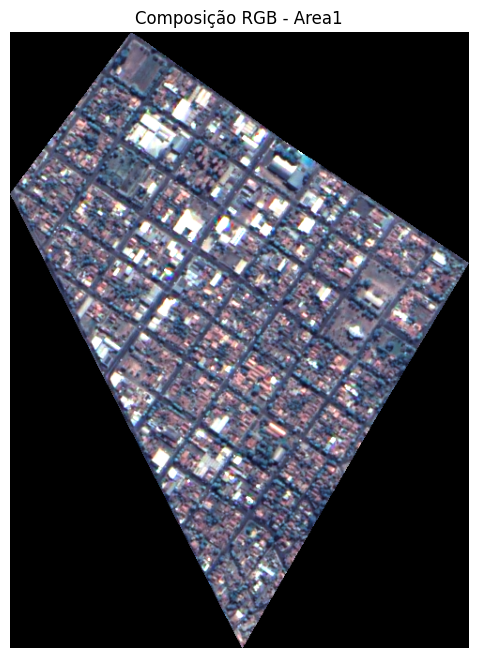

In [ ]:
vermelho = ajustar_visualizacao(imagem[2])
verde = ajustar_visualizacao(imagem[1])
azul = ajustar_visualizacao(imagem[0])

rgb = np.dstack((vermelho, verde, azul))

plt.figure(figsize=(8, 8))
plt.imshow(rgb)
plt.title("Composição RGB - Area1")
plt.axis("off")
plt.show()

# Parte 2 — Geração de patches e definição das classes.

### 1- Geração dos patches



* (32, 16): patch de 32×32 pixels, avançando 16 pixels.
* (64, 32): patch de 64×64 pixels, avançando 32 pixels.
* (96, 48): patch de 96×96 pixels, avançando 48 pixels.
* (128, 64): patch de 128×128 pixels, avançando 64 pixels.



In [ ]:
from rasterio.windows import Window

# Configurações de tamanho do patch e stride
configuracoes = [
    (32, 16),
    (64, 32),
    (96, 48),
    (128, 64)
]

patches = []

for tamanho_patch, stride in configuracoes:

    for linha in range(0, src.height - tamanho_patch + 1, stride):
        for coluna in range(0, src.width - tamanho_patch + 1, stride):

            janela = Window(
                coluna,
                linha,
                tamanho_patch,
                tamanho_patch
            )

            patch = src.read(window=janela)

            patches.append({
                "tamanho_patch": tamanho_patch,
                "stride": stride,
                "linha": linha,
                "coluna": coluna,
                "dados": patch
            })

print("===== RESUMO DA GERAÇÃO DOS PATCHES =====")

for tamanho_patch, stride in configuracoes:

    quantidade = sum(
        item["tamanho_patch"] == tamanho_patch
        for item in patches
    )

    print(f"Patches de {tamanho_patch} x {tamanho_patch}: {quantidade}")

print()
print("Quantidade total de patches gerados:", len(patches))


===== RESUMO DA GERAÇÃO DOS PATCHES =====
Patches de 32 x 32: 1160
Patches de 64 x 64: 266
Patches de 96 x 96: 108
Patches de 128 x 128: 54

Quantidade total de patches gerados: 1588


### 2- Verificação de NoData

In [ ]:
patches_com_nodata = 0
patches_sem_nodata = 0

for item in patches:
    patch = item["dados"]

    if np.any(np.all(patch == src.nodata, axis=0)):
        patches_com_nodata += 1
    else:
        patches_sem_nodata += 1

print("Total de patches:", len(patches))
print("Patches com NoData:", patches_com_nodata)
print("Patches sem NoData:", patches_sem_nodata)

Total de patches: 1588
Patches com NoData: 987
Patches sem NoData: 601


### 3- Cálculo do percentual de NoData

Calculo para avaliar quanto de cada recorte contém informações válidas antes de selecionar os patches que serão utilizados nas próximas etapas.


In [ ]:
percentuais_nodata = []

for item in patches:
    patch = item["dados"]

    # Identifica posições espaciais sem dados
    mascara_nodata = np.all(patch == src.nodata, axis=0)

    # Calcula a porcentagem de NoData no patch
    percentual = mascara_nodata.mean() * 100

    # Guarda o resultado no próprio patch
    item["percentual_nodata"] = percentual

    percentuais_nodata.append(percentual)

print("Menor percentual de NoData:", min(percentuais_nodata))
print("Maior percentual de NoData:", max(percentuais_nodata))
print("Média de NoData:", np.mean(percentuais_nodata))


# Análise do NoData separada por tamanho de patch

print("\n===== NODATA POR TAMANHO DE PATCH =====")

for tamanho_patch, stride in configuracoes:

    # Seleciona os patches do tamanho atual
    patches_tamanho = [
        item for item in patches
        if item["tamanho_patch"] == tamanho_patch
    ]

    # Obtém os percentuais de NoData desses patches
    percentuais_tamanho = [
        item["percentual_nodata"]
        for item in patches_tamanho
    ]

    print(f"\nPatches de {tamanho_patch} x {tamanho_patch}")
    print("Quantidade:", len(patches_tamanho))
    print("Menor percentual de NoData:", min(percentuais_tamanho))
    print("Maior percentual de NoData:", max(percentuais_tamanho))
    print("Média de NoData:", np.mean(percentuais_tamanho))

Menor percentual de NoData: 0.0
Maior percentual de NoData: 100.0
Média de NoData: 46.42920847737152

===== NODATA POR TAMANHO DE PATCH =====

Patches de 32 x 32
Quantidade: 1160
Menor percentual de NoData: 0.0
Maior percentual de NoData: 100.0
Média de NoData: 47.97043372844828

Patches de 64 x 64
Quantidade: 266
Menor percentual de NoData: 0.0
Maior percentual de NoData: 100.0
Média de NoData: 44.139156484962406

Patches de 96 x 96
Quantidade: 108
Menor percentual de NoData: 0.0
Maior percentual de NoData: 100.0
Média de NoData: 40.47449684927983

Patches de 128 x 128
Quantidade: 54
Menor percentual de NoData: 0.0
Maior percentual de NoData: 100.0
Média de NoData: 36.51145652488426


### Gráfico do percentual médio de NoData por tamanho de patch

A média de NoData diminuiu conforme aumentamos o tamanho dos patches.

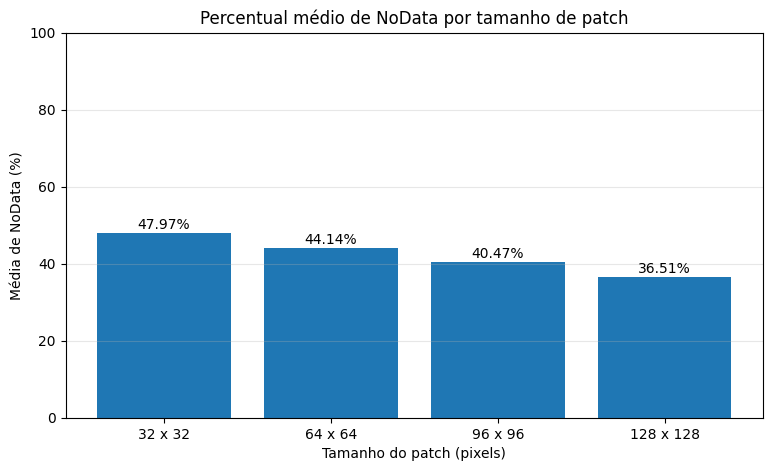

In [ ]:
tamanhos = []
medias_nodata = []

# Calcula a média de NoData para cada tamanho
for tamanho_patch, stride in configuracoes:

    percentuais_tamanho = [
        item["percentual_nodata"]
        for item in patches
        if item["tamanho_patch"] == tamanho_patch
    ]

    tamanhos.append(f"{tamanho_patch} x {tamanho_patch}")
    medias_nodata.append(np.mean(percentuais_tamanho))

# Criação do gráfico
plt.figure(figsize=(9, 5))

barras = plt.bar(tamanhos, medias_nodata)

# Exibe o percentual acima de cada barra
for barra, media in zip(barras, medias_nodata):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 1,
        f"{media:.2f}%",
        ha="center"
    )

plt.title("Percentual médio de NoData por tamanho de patch")
plt.xlabel("Tamanho do patch (pixels)")
plt.ylabel("Média de NoData (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.show()

### 4- Quantificação de patches com dados válidos e completamente vazios

In [ ]:
# Etapa 4 — Quantificação de patches válidos e vazios

print("===== ANÁLISE GERAL =====")

print("Total de patches:", len(patches))

print("Patches com dados válidos:",
      sum(p < 100 for p in percentuais_nodata))

print("Patches completamente vazios:",
      sum(p == 100 for p in percentuais_nodata))


print("\n===== ANÁLISE POR TAMANHO =====")

for tamanho_patch, stride in configuracoes:

    patches_tamanho = [
        item for item in patches
        if item["tamanho_patch"] == tamanho_patch
    ]

    patches_com_dados = sum(
        item["percentual_nodata"] < 100
        for item in patches_tamanho
    )

    patches_vazios = sum(
        item["percentual_nodata"] == 100
        for item in patches_tamanho
    )

    print(f"\nPatches de {tamanho_patch} x {tamanho_patch}")
    print("Total:", len(patches_tamanho))
    print("Com dados válidos:", patches_com_dados)
    print("Completamente vazios:", patches_vazios)

===== ANÁLISE GERAL =====
Total de patches: 1588
Patches com dados válidos: 1073
Patches completamente vazios: 515

===== ANÁLISE POR TAMANHO =====

Patches de 32 x 32
Total: 1160
Com dados válidos: 726
Completamente vazios: 434

Patches de 64 x 64
Total: 266
Com dados válidos: 203
Completamente vazios: 63

Patches de 96 x 96
Total: 108
Com dados válidos: 93
Completamente vazios: 15

Patches de 128 x 128
Total: 54
Com dados válidos: 51
Completamente vazios: 3


### 5- Visualização de patches representativos

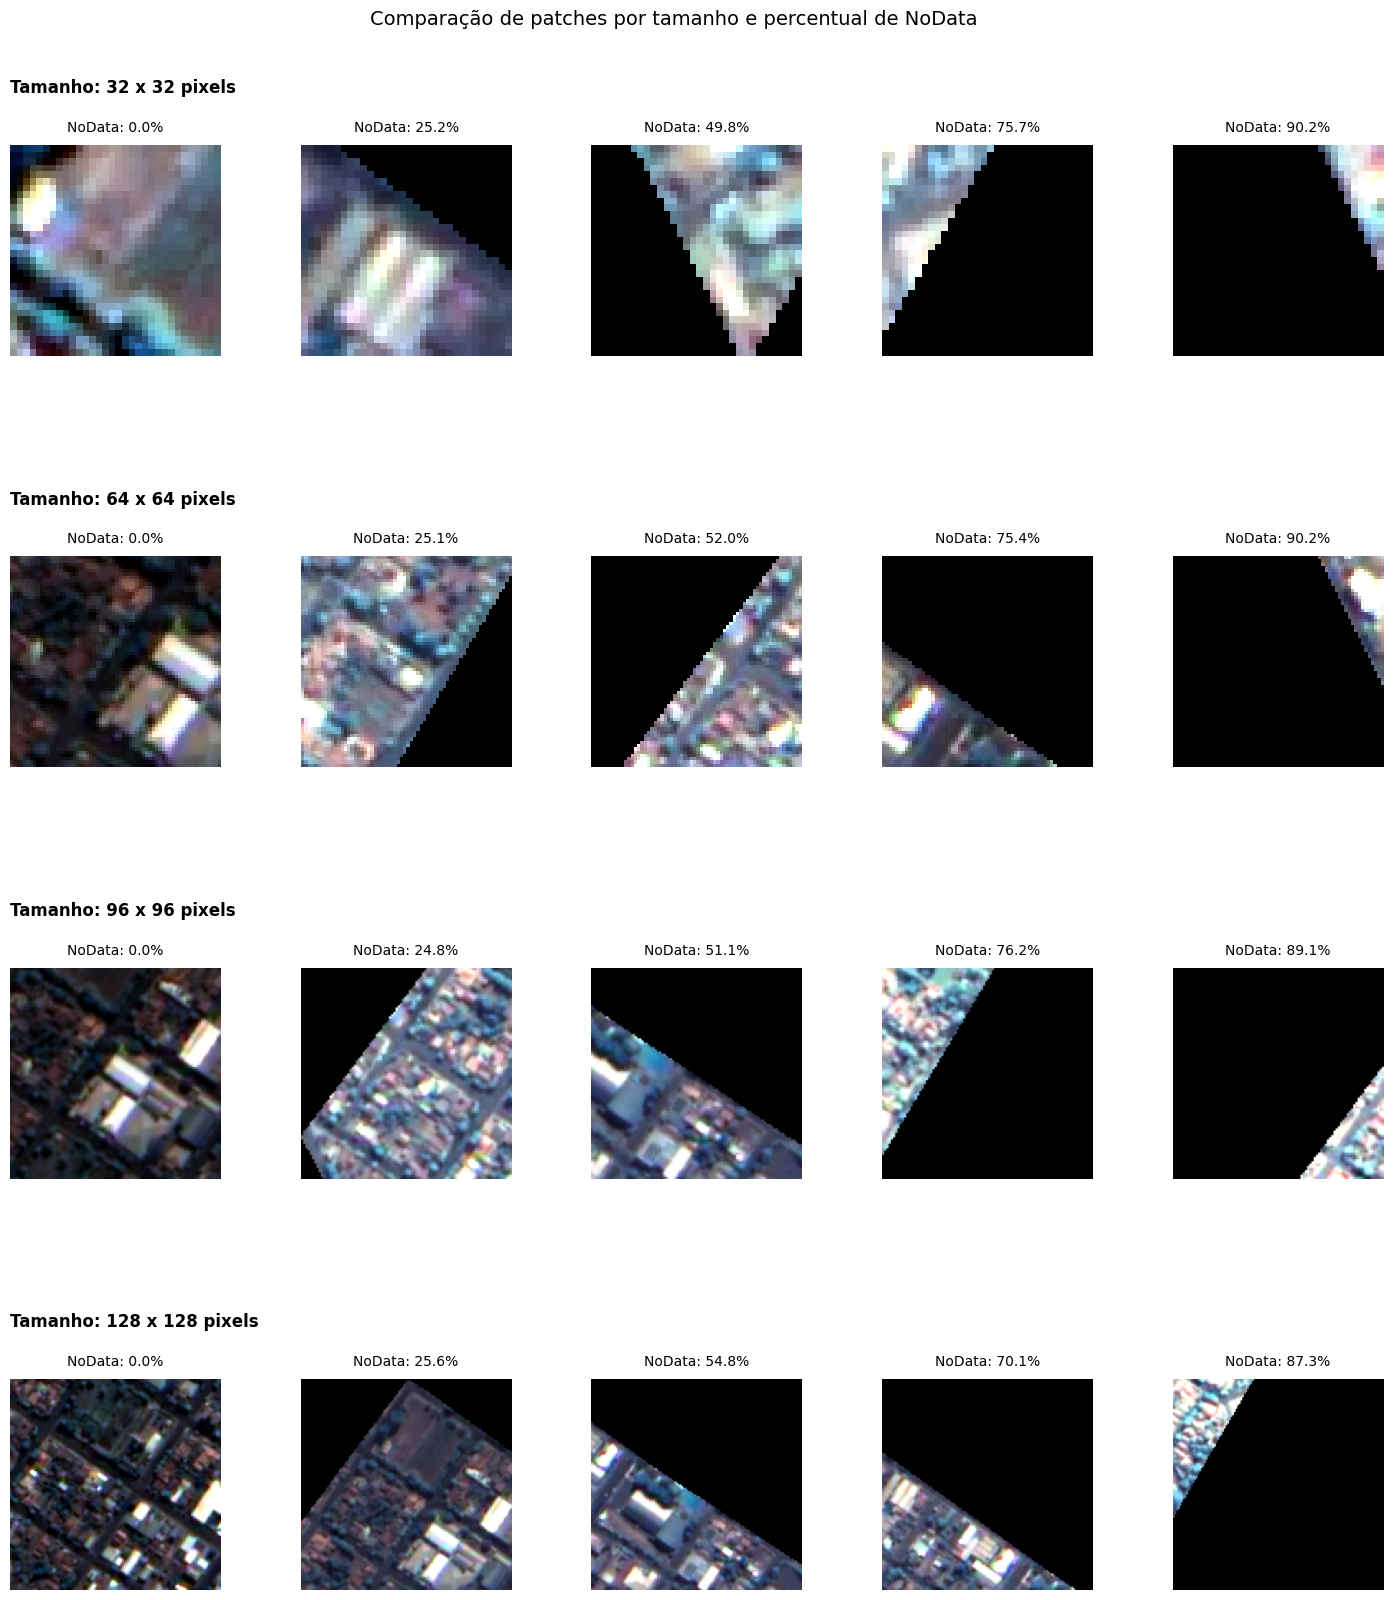

In [ ]:
# Etapa 5 — Visualização de patches representativos

# Percentuais de NoData que queremos comparar
percentuais_desejados = [0, 25, 50, 75, 90]

# Função para encontrar um patch próximo ao percentual desejado
def encontrar_patch_proximo(tamanho, percentual_desejado):

    patches_tamanho = [
        item for item in patches
        if item["tamanho_patch"] == tamanho
    ]

    return min(
        patches_tamanho,
        key=lambda item: abs(
            item["percentual_nodata"] - percentual_desejado
        )
    )


# Criar a figura com 4 linhas e 5 colunas
fig, axes = plt.subplots(
    len(configuracoes),
    len(percentuais_desejados),
    figsize=(18, 17)
)

# Percorrer cada tamanho de patch
for i, (tamanho_patch, stride) in enumerate(configuracoes):

    # Percorrer cada percentual desejado
    for j, percentual_desejado in enumerate(percentuais_desejados):

        item = encontrar_patch_proximo(
            tamanho_patch,
            percentual_desejado
        )

        patch = item["dados"]

        # Composição RGB
        vermelho = ajustar_visualizacao(patch[2])
        verde = ajustar_visualizacao(patch[1])
        azul = ajustar_visualizacao(patch[0])

        patch_rgb = np.dstack(
            (vermelho, verde, azul)
        )

        # Mostrar o patch
        axes[i, j].imshow(patch_rgb)

        # Mostrar somente o percentual de NoData
        axes[i, j].set_title(
            f"NoData: {item['percentual_nodata']:.1f}%",
            fontsize=10,
            pad=10
        )

        axes[i, j].axis("off")

    # Mostrar o tamanho apenas uma vez por linha
    axes[i, 0].annotate(
        f"Tamanho: {tamanho_patch} x {tamanho_patch} pixels",
        xy=(0, 1.25),
        xycoords="axes fraction",
        fontsize=12,
        fontweight="bold",
        ha="left",
        annotation_clip=False
    )


# Título principal
fig.suptitle(
    "Comparação de patches por tamanho e percentual de NoData",
    fontsize=14,
    y=0.98
)

# Ajustar os espaços entre títulos e imagens
fig.subplots_adjust(
    top=0.90,
    bottom=0.05,
    hspace=0.95,
    wspace=0.25
)

plt.show()

### 6- Seleção dos patches válidos

In [ ]:
# Etapa 6 — Seleção dos patches conforme a presença de NoData

# Patches totalmente preenchidos com dados
patches_sem_nodata = [
    item for item in patches
    if item["percentual_nodata"] == 0
]

# Patches parcialmente preenchidos com dados
patches_nodata_parcial = [
    item for item in patches
    if 0 < item["percentual_nodata"] < 100
]

# Patches completamente vazios
patches_vazios = [
    item for item in patches
    if item["percentual_nodata"] == 100
]

# Preservar todos os patches que possuem algum dado válido
patches_validos = patches_sem_nodata + patches_nodata_parcial

# Descartar apenas os completamente vazios
patches_descartados = patches_vazios

# Resumo geral
print("===== SELEÇÃO DOS PATCHES =====")
print("Total de patches:", len(patches))
print("Sem NoData:", len(patches_sem_nodata))
print("Com NoData parcial:", len(patches_nodata_parcial))
print("Completamente vazios:", len(patches_vazios))

print()
print("Patches preservados:", len(patches_validos))
print("Patches descartados:", len(patches_descartados))

# Resumo por tamanho
print("\n===== SELEÇÃO POR TAMANHO =====")

for tamanho_patch, stride in configuracoes:

    patches_tamanho = [
        item for item in patches
        if item["tamanho_patch"] == tamanho_patch
    ]

    sem_nodata = sum(
        item["percentual_nodata"] == 0
        for item in patches_tamanho
    )

    nodata_parcial = sum(
        0 < item["percentual_nodata"] < 100
        for item in patches_tamanho
    )

    vazios = sum(
        item["percentual_nodata"] == 100
        for item in patches_tamanho
    )

    print(f"\nPatches de {tamanho_patch} x {tamanho_patch}")
    print("Sem NoData:", sem_nodata)
    print("Com NoData parcial:", nodata_parcial)
    print("Completamente vazios:", vazios)
    print("Preservados:", sem_nodata + nodata_parcial)

===== SELEÇÃO DOS PATCHES =====
Total de patches: 1588
Sem NoData: 601
Com NoData parcial: 472
Completamente vazios: 515

Patches preservados: 1073
Patches descartados: 515

===== SELEÇÃO POR TAMANHO =====

Patches de 32 x 32
Sem NoData: 474
Com NoData parcial: 252
Completamente vazios: 434
Preservados: 726

Patches de 64 x 64
Sem NoData: 89
Com NoData parcial: 114
Completamente vazios: 63
Preservados: 203

Patches de 96 x 96
Sem NoData: 28
Com NoData parcial: 65
Completamente vazios: 15
Preservados: 93

Patches de 128 x 128
Sem NoData: 10
Com NoData parcial: 41
Completamente vazios: 3
Preservados: 51


### 7- Salvamento dos patches válidos como GeoTIFF
Os arquivos são separados conforme suas dimensões, preservando as quatro bandas, os valores originais dos pixels, o sistema de referência e o georreferenciamento. A identificação por tamanho, linha e coluna permite localizar cada recorte na imagem original.

In [ ]:
# Etapa 7 — Salvamento dos patches válidos no Google Drive

import os
from rasterio.windows import Window
from rasterio.windows import transform

# Pasta principal onde os patches serão salvos
pasta_saida = "/content/drive/MyDrive/CBERS4A/patches_validos"

os.makedirs(pasta_saida, exist_ok=True)

# Salvar os patches válidos
for item in patches_validos:

    tamanho_patch = item["tamanho_patch"]
    linha = item["linha"]
    coluna = item["coluna"]
    patch = item["dados"]

    # Criar uma pasta para cada tamanho de patch
    pasta_tamanho = os.path.join(
        pasta_saida,
        f"{tamanho_patch}x{tamanho_patch}"
    )

    os.makedirs(pasta_tamanho, exist_ok=True)

    # Janela correspondente ao patch
    janela = Window(
        coluna,
        linha,
        tamanho_patch,
        tamanho_patch
    )

    # Calcular o georreferenciamento do patch
    transform_patch = transform(janela, src.transform)

    # Nome do arquivo
    nome_arquivo = (
        f"patch_{tamanho_patch}x{tamanho_patch}"
        f"_L{linha}_C{coluna}.tif"
    )

    caminho_saida = os.path.join(
        pasta_tamanho,
        nome_arquivo
    )

    # Salvar o patch como GeoTIFF
    with rasterio.open(
        caminho_saida,
        "w",
        driver="GTiff",
        height=tamanho_patch,
        width=tamanho_patch,
        count=src.count,
        dtype=src.dtypes[0],
        crs=src.crs,
        transform=transform_patch,
        nodata=src.nodata
    ) as dst:

        dst.write(patch)

print("===== SALVAMENTO DOS PATCHES =====")
print("Pasta de destino:", pasta_saida)
print("Total de patches salvos:", len(patches_validos))

print("\n===== PATCHES SALVOS POR TAMANHO =====")

for tamanho_patch, stride in configuracoes:

    quantidade = sum(
        item["tamanho_patch"] == tamanho_patch
        for item in patches_validos
    )

    print(f"{tamanho_patch} x {tamanho_patch}: {quantidade}")

===== SALVAMENTO DOS PATCHES =====
Pasta de destino: /content/drive/MyDrive/CBERS4A/patches_validos
Total de patches salvos: 1073

===== PATCHES SALVOS POR TAMANHO =====
32 x 32: 726
64 x 64: 203
96 x 96: 93
128 x 128: 51


### 8- Criação da tabela de patches

In [ ]:
# Etapa 8 — Criação da tabela de patches

import pandas as pd

registros = []

for item in patches_validos:

    tamanho_patch = item["tamanho_patch"]
    stride = item["stride"]
    linha = item["linha"]
    coluna = item["coluna"]

    # Nome do arquivo salvo na Etapa 7
    nome_arquivo = (
        f"patch_{tamanho_patch}x{tamanho_patch}"
        f"_L{linha}_C{coluna}.tif"
    )

    # Caminho do arquivo no Google Drive
    caminho_arquivo = os.path.join(
        pasta_saida,
        f"{tamanho_patch}x{tamanho_patch}",
        nome_arquivo
    )

    # Registrar as informações do patch
    registros.append({
        "arquivo": nome_arquivo,
        "caminho": caminho_arquivo,
        "tamanho_patch": tamanho_patch,
        "stride": stride,
        "linha": linha,
        "coluna": coluna,
        "percentual_nodata": item["percentual_nodata"],
        "codigo_classe": "",
        "classe": ""
    })

# Criar a tabela
tabela_patches = pd.DataFrame(registros)

# Salvar a tabela no Google Drive
caminho_csv = os.path.join(
    pasta_saida,
    "tabela_patches.csv"
)

tabela_patches.to_csv(
    caminho_csv,
    index=False
)

# Apresentar o resumo
print("===== TABELA DE PATCHES =====")
print("Total de registros:", len(tabela_patches))
print("Tabela salva em:", caminho_csv)

print("\n===== REGISTROS POR TAMANHO =====")

for tamanho_patch, stride in configuracoes:

    quantidade = sum(
        tabela_patches["tamanho_patch"] == tamanho_patch
    )

    print(f"{tamanho_patch} x {tamanho_patch}: {quantidade}")

print("\n===== PRIMEIROS REGISTROS =====")

display(tabela_patches.head())

===== TABELA DE PATCHES =====
Total de registros: 1073
Tabela salva em: /content/drive/MyDrive/CBERS4A/patches_validos/tabela_patches.csv

===== REGISTROS POR TAMANHO =====
32 x 32: 726
64 x 64: 203
96 x 96: 93
128 x 128: 51

===== PRIMEIROS REGISTROS =====


,arquivo,caminho,tamanho_patch,stride,linha,coluna,percentual_nodata,codigo_classe,classe
0,patch_32x32_L32_C112.tif,/content/drive/MyDrive/CBERS4A/patches_validos...,32,16,32,112,0.0,,
1,patch_32x32_L32_C128.tif,/content/drive/MyDrive/CBERS4A/patches_validos...,32,16,32,128,0.0,,
2,patch_32x32_L32_C144.tif,/content/drive/MyDrive/CBERS4A/patches_validos...,32,16,32,144,0.0,,
3,patch_32x32_L48_C96.tif,/content/drive/MyDrive/CBERS4A/patches_validos...,32,16,48,96,0.0,,
4,patch_32x32_L48_C112.tif,/content/drive/MyDrive/CBERS4A/patches_validos...,32,16,48,112,0.0,,


### 9- Conferência dos arquivos gerados


In [ ]:
# Etapa 9 — Conferência dos arquivos gerados

import os

print("===== CONFERÊNCIA DOS ARQUIVOS =====")

total_arquivos = 0

# Conferir os arquivos de cada tamanho
for tamanho_patch, stride in configuracoes:

    pasta_tamanho = os.path.join(
        pasta_saida,
        f"{tamanho_patch}x{tamanho_patch}"
    )

    # Listar apenas os arquivos GeoTIFF
    arquivos = [
        arquivo for arquivo in os.listdir(pasta_tamanho)
        if arquivo.lower().endswith(".tif")
    ]

    quantidade_arquivos = len(arquivos)

    # Quantidade esperada conforme a tabela CSV
    quantidade_esperada = sum(
        tabela_patches["tamanho_patch"] == tamanho_patch
    )

    total_arquivos += quantidade_arquivos

    print(f"\nPatches de {tamanho_patch} x {tamanho_patch}")
    print("Arquivos encontrados:", quantidade_arquivos)
    print("Registros na tabela:", quantidade_esperada)

    if quantidade_arquivos == quantidade_esperada:
        print("Situação: OK")
    else:
        print("Situação: DIVERGÊNCIA")

# Conferir o total
print("\n===== RESUMO GERAL =====")
print("Total de arquivos GeoTIFF:", total_arquivos)
print("Total de registros na tabela:", len(tabela_patches))

# Conferir se o CSV existe
print("\n===== CONFERÊNCIA DO CSV =====")

if os.path.exists(caminho_csv):
    print("Tabela CSV encontrada.")
    print("Local:", caminho_csv)
else:
    print("ATENÇÃO: Tabela CSV não encontrada.")

# Conferir se todos os arquivos registrados na tabela existem
arquivos_ausentes = [
    caminho for caminho in tabela_patches["caminho"]
    if not os.path.isfile(caminho)
]

print("\n===== VERIFICAÇÃO DOS CAMINHOS =====")
print("Arquivos ausentes:", len(arquivos_ausentes))

if len(arquivos_ausentes) == 0:
    print("Todos os arquivos registrados na tabela foram encontrados.")
else:
    print("ATENÇÃO: Existem arquivos registrados que não foram encontrados.")
    print("Exemplos:", arquivos_ausentes[:5])

===== CONFERÊNCIA DOS ARQUIVOS =====

Patches de 32 x 32
Arquivos encontrados: 726
Registros na tabela: 726
Situação: OK

Patches de 64 x 64
Arquivos encontrados: 203
Registros na tabela: 203
Situação: OK

Patches de 96 x 96
Arquivos encontrados: 93
Registros na tabela: 93
Situação: OK

Patches de 128 x 128
Arquivos encontrados: 51
Registros na tabela: 51
Situação: OK

===== RESUMO GERAL =====
Total de arquivos GeoTIFF: 1073
Total de registros na tabela: 1073

===== CONFERÊNCIA DO CSV =====
Tabela CSV encontrada.
Local: /content/drive/MyDrive/CBERS4A/patches_validos/tabela_patches.csv

===== VERIFICAÇÃO DOS CAMINHOS =====
Arquivos ausentes: 0
Todos os arquivos registrados na tabela foram encontrados.


### 10- Verificação de um patch salvo (patch_000.tif)



===== VERIFICAÇÃO DOS PATCHES SALVOS =====

===== PATCH 32 x 32 =====
Arquivo: patch_32x32_L32_C112.tif
Dimensões: 32 x 32
Quantidade de bandas: 4
Tipo de dado: uint16
Sistema de referência: EPSG:32722
NoData: 0.0
Transformação espacial: | 2.00, 0.00, 492706.00|
| 0.00,-2.00, 7602990.00|
| 0.00, 0.00, 1.00|
Percentual de NoData: 0.00%

===== PATCH 64 x 64 =====
Arquivo: patch_64x64_L64_C96.tif
Dimensões: 64 x 64
Quantidade de bandas: 4
Tipo de dado: uint16
Sistema de referência: EPSG:32722
NoData: 0.0
Transformação espacial: | 2.00, 0.00, 492674.00|
| 0.00,-2.00, 7602926.00|
| 0.00, 0.00, 1.00|
Percentual de NoData: 0.00%

===== PATCH 96 x 96 =====
Arquivo: patch_96x96_L48_C96.tif
Dimensões: 96 x 96
Quantidade de bandas: 4
Tipo de dado: uint16
Sistema de referência: EPSG:32722
NoData: 0.0
Transformação espacial: | 2.00, 0.00, 492674.00|
| 0.00,-2.00, 7602958.00|
| 0.00, 0.00, 1.00|
Percentual de NoData: 0.00%

===== PATCH 128 x 128 =====
Arquivo: patch_128x128_L128_C64.tif
Dimensões: 1

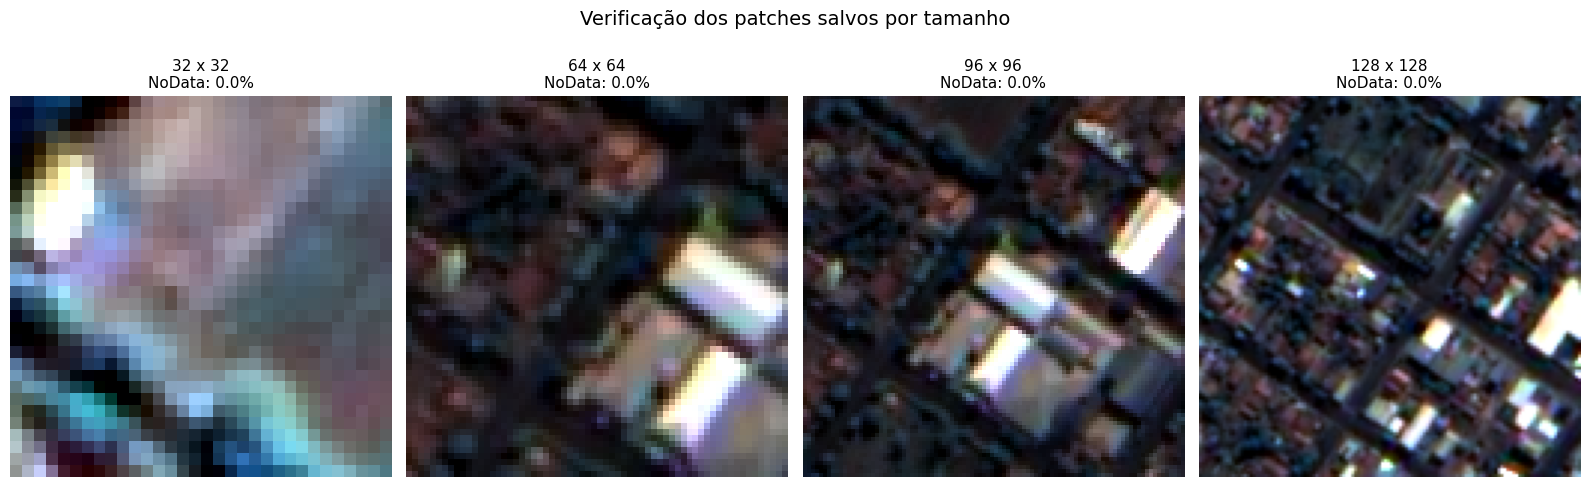

In [ ]:
# Etapa 10 — Verificação de um patch salvo de cada tamanho

import rasterio
import matplotlib.pyplot as plt
import numpy as np
import os

# Criar uma figura com uma imagem para cada tamanho
fig, axes = plt.subplots(1, len(configuracoes), figsize=(16, 5))

print("===== VERIFICAÇÃO DOS PATCHES SALVOS =====")

for i, (tamanho_patch, stride) in enumerate(configuracoes):

    # Selecionar um patch sem NoData para facilitar a comparação
    candidatos = [
        item for item in patches_sem_nodata
        if item["tamanho_patch"] == tamanho_patch
    ]

    # Selecionar o primeiro patch disponível
    item = candidatos[0]

    linha = item["linha"]
    coluna = item["coluna"]

    # Nome do arquivo salvo na Etapa 7
    nome_arquivo = (
        f"patch_{tamanho_patch}x{tamanho_patch}"
        f"_L{linha}_C{coluna}.tif"
    )

    # Caminho no Google Drive
    caminho_arquivo = os.path.join(
        pasta_saida,
        f"{tamanho_patch}x{tamanho_patch}",
        nome_arquivo
    )

    # Abrir o GeoTIFF salvo
    with rasterio.open(caminho_arquivo) as patch_salvo:

        dados = patch_salvo.read()

        print(f"\n===== PATCH {tamanho_patch} x {tamanho_patch} =====")
        print("Arquivo:", nome_arquivo)
        print("Dimensões:", patch_salvo.width, "x", patch_salvo.height)
        print("Quantidade de bandas:", patch_salvo.count)
        print("Tipo de dado:", patch_salvo.dtypes[0])
        print("Sistema de referência:", patch_salvo.crs)
        print("NoData:", patch_salvo.nodata)
        print("Transformação espacial:", patch_salvo.transform)

        # Calcular o percentual de NoData do arquivo salvo
        mascara_nodata = np.all(
            dados == patch_salvo.nodata,
            axis=0
        )

        percentual_nodata = mascara_nodata.mean() * 100

        print(f"Percentual de NoData: {percentual_nodata:.2f}%")

        # Composição RGB
        vermelho = ajustar_visualizacao(dados[2])
        verde = ajustar_visualizacao(dados[1])
        azul = ajustar_visualizacao(dados[0])

        patch_rgb = np.dstack(
            (vermelho, verde, azul)
        )

        # Exibir o patch
        axes[i].imshow(patch_rgb)

        axes[i].set_title(
            f"{tamanho_patch} x {tamanho_patch}\n"
            f"NoData: {percentual_nodata:.1f}%",
            fontsize=11
        )

        axes[i].axis("off")

# Título principal
fig.suptitle(
    "Verificação dos patches salvos por tamanho",
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.show()

### 11- Definição das Classes

### 11.1- Classificação com 2 classes
*   **Arbórea:** árvores e vegetação de porte elevado.
*   **Outros:** edificações, vias pavimentadas, solo exposto, vegetação rasteira e demais alvos urbanos.

In [ ]:
classes_2 = {
    0: "Outros",
    1: "Vegetação arbórea"
}

print("===== CLASSIFICAÇÃO COM 2 CLASSES =====")

for codigo, nome in classes_2.items():
    print(f"Classe {codigo}: {nome}")

===== CLASSIFICAÇÃO COM 2 CLASSES =====
Classe 0: Outros
Classe 1: Vegetação arbórea


### 11.2- Classificação com 5 classes
*   **Edificado:** construções e edificações.
*   **Superfície impermeável:** ruas, calçadas e outras superfícies pavimentadas.
* **Solo exposto**: áreas sem cobertura vegetal ou construída
* **Vegetação arbórea:** árvores e áreas de cobertura arbórea
* **Vegetação rasteira:** gramados e vegetação de pequeno porte

In [ ]:
classes_5 = {
    0: "Edificado",
    1: "Superfície impermeável",
    2: "Solo exposto",
    3: "Vegetação arbórea",
    4: "Vegetação rasteira"
}

print("===== CLASSIFICAÇÃO COM 5 CLASSES =====")

for codigo, nome in classes_5.items():
    print(f"Classe {codigo}: {nome}")

===== CLASSIFICAÇÃO COM 5 CLASSES =====
Classe 0: Edificado
Classe 1: Superfície impermeável
Classe 2: Solo exposto
Classe 3: Vegetação arbórea
Classe 4: Vegetação rasteira


### 12- Área coberta e contexto espacial dos patches

A resolução espacial da imagem é de 2 m/pixel. Dessa forma, foram calculadas as dimensões no terreno correspondentes aos quatro tamanhos de patches utilizados: 32 × 32, 64 × 64, 96 × 96 e 128 × 128 pixels, que representam áreas de 64 × 64 m, 128 × 128 m, 192 × 192 m e 256 × 256 m, respectivamente.

Os diferentes tamanhos de patches permitem avaliar a representação dos elementos arbóreos e de sua vizinhança urbana, incluindo edificações, vias e outras coberturas do solo. Os patches menores abrangem áreas mais localizadas, enquanto os maiores oferecem maior contexto espacial.

Foi utilizada uma sobreposição de 50% entre patches consecutivos nas direções horizontal e vertical, permitindo gerar recortes parcialmente sobrepostos e preservar diferentes representações dos elementos próximos às bordas dos patches.

In [ ]:
# Resolução espacial da imagem
resolucao_x, resolucao_y = src.res

print("===== ÁREA COBERTA E CONTEXTO ESPACIAL =====")
print(f"Resolução espacial: {resolucao_x} x {resolucao_y} m/pixel")

# Calcular as informações de cada configuração
for tamanho_patch, stride in configuracoes:

    # Dimensão do patch no terreno
    largura_patch_m = tamanho_patch * resolucao_x
    altura_patch_m = tamanho_patch * resolucao_y

    # Área do patch
    area_patch_m2 = largura_patch_m * altura_patch_m

    # Deslocamento do stride no terreno
    stride_x_m = stride * resolucao_x
    stride_y_m = stride * resolucao_y

    # Sobreposição entre patches consecutivos em cada direção
    sobreposicao = (1 - stride / tamanho_patch) * 100

    print(f"\n===== PATCH {tamanho_patch} x {tamanho_patch} =====")
    print("Dimensão no terreno:",
          largura_patch_m, "x", altura_patch_m, "m")
    print("Área do patch:", area_patch_m2, "m²")
    print("Stride:", stride, "pixels")
    print("Deslocamento no terreno:",
          stride_x_m, "x", stride_y_m, "m")
    print("Sobreposição por direção:", sobreposicao, "%")

===== ÁREA COBERTA E CONTEXTO ESPACIAL =====
Resolução espacial: 2.0 x 2.0 m/pixel

===== PATCH 32 x 32 =====
Dimensão no terreno: 64.0 x 64.0 m
Área do patch: 4096.0 m²
Stride: 16 pixels
Deslocamento no terreno: 32.0 x 32.0 m
Sobreposição por direção: 50.0 %

===== PATCH 64 x 64 =====
Dimensão no terreno: 128.0 x 128.0 m
Área do patch: 16384.0 m²
Stride: 32 pixels
Deslocamento no terreno: 64.0 x 64.0 m
Sobreposição por direção: 50.0 %

===== PATCH 96 x 96 =====
Dimensão no terreno: 192.0 x 192.0 m
Área do patch: 36864.0 m²
Stride: 48 pixels
Deslocamento no terreno: 96.0 x 96.0 m
Sobreposição por direção: 50.0 %

===== PATCH 128 x 128 =====
Dimensão no terreno: 256.0 x 256.0 m
Área do patch: 65536.0 m²
Stride: 64 pixels
Deslocamento no terreno: 128.0 x 128.0 m
Sobreposição por direção: 50.0 %


### 13- Síntese da geração dos patches

A imagem foi inicialmente dividida em patches de 64 × 64 pixels utilizando stride de 32 pixels.

Como a área válida do raster não ocupa toda a matriz retangular da imagem, foram encontrados patches contendo diferentes proporções de pixels NoData. Após a análise da distribuição e a inspeção visual de patches representativos, foi adotado para este conjunto o critério de manter patches com até 25% de NoData.

Os patches selecionados foram armazenados individualmente em formato GeoTIFF, preservando as quatro bandas, o georreferenciamento, a resolução espacial e o valor NoData do raster.

O conjunto resultante, juntamente com as classes Arbórea e Outros formalmente definidas, fica preparado para a etapa seguinte de coleta de amostras e rotulação.

In [ ]:
# Etapa 13 — Síntese da geração dos patches

print("===== RESUMO DA GERAÇÃO DOS PATCHES =====")

print("Patches gerados:", len(patches))
print("Patches sem NoData:", len(patches_sem_nodata))
print("Patches com NoData parcial:", len(patches_nodata_parcial))
print("Patches preservados:", len(patches_validos))
print("Patches descartados (100% NoData):", len(patches_descartados))

# Resumo por tamanho
print("\n===== RESULTADOS POR TAMANHO =====")

for tamanho_patch, stride in configuracoes:

    quantidade_gerada = sum(
        item["tamanho_patch"] == tamanho_patch
        for item in patches
    )

    quantidade_preservada = sum(
        item["tamanho_patch"] == tamanho_patch
        for item in patches_validos
    )

    quantidade_descartada = sum(
        item["tamanho_patch"] == tamanho_patch
        for item in patches_descartados
    )

    print(f"\nPatch {tamanho_patch} x {tamanho_patch}")
    print("Gerados:", quantidade_gerada)
    print("Preservados:", quantidade_preservada)
    print("Descartados:", quantidade_descartada)

    # Características espaciais
    largura_m = tamanho_patch * src.res[0]
    altura_m = tamanho_patch * src.res[1]
    area_m2 = largura_m * altura_m
    stride_m = stride * src.res[0]
    sobreposicao = (1 - stride / tamanho_patch) * 100

    print(f"Dimensão no terreno: {largura_m} x {altura_m} m")
    print(f"Área: {area_m2} m²")
    print(f"Stride: {stride} pixels ({stride_m} m)")
    print(f"Sobreposição por direção: {sobreposicao:.1f}%")

# Classes da sua pesquisa
print("\n===== CLASSIFICAÇÃO COM 2 CLASSES =====")

for codigo, nome in classes_2.items():
    print(f"{codigo}: {nome}")

# Classes da pesquisa da sua colega
print("\n===== CLASSIFICAÇÃO COM 5 CLASSES =====")

for codigo, nome in classes_5.items():
    print(f"{codigo}: {nome}")

# Arquivos salvos
print("\n===== ARMAZENAMENTO =====")
print("Pasta dos patches:", pasta_saida)
print("Tabela CSV:", caminho_csv)

===== RESUMO DA GERAÇÃO DOS PATCHES =====
Patches gerados: 1588
Patches sem NoData: 601
Patches com NoData parcial: 472
Patches preservados: 1073
Patches descartados (100% NoData): 515

===== RESULTADOS POR TAMANHO =====

Patch 32 x 32
Gerados: 1160
Preservados: 726
Descartados: 434
Dimensão no terreno: 64.0 x 64.0 m
Área: 4096.0 m²
Stride: 16 pixels (32.0 m)
Sobreposição por direção: 50.0%

Patch 64 x 64
Gerados: 266
Preservados: 203
Descartados: 63
Dimensão no terreno: 128.0 x 128.0 m
Área: 16384.0 m²
Stride: 32 pixels (64.0 m)
Sobreposição por direção: 50.0%

Patch 96 x 96
Gerados: 108
Preservados: 93
Descartados: 15
Dimensão no terreno: 192.0 x 192.0 m
Área: 36864.0 m²
Stride: 48 pixels (96.0 m)
Sobreposição por direção: 50.0%

Patch 128 x 128
Gerados: 54
Preservados: 51
Descartados: 3
Dimensão no terreno: 256.0 x 256.0 m
Área: 65536.0 m²
Stride: 64 pixels (128.0 m)
Sobreposição por direção: 50.0%

===== CLASSIFICAÇÃO COM 2 CLASSES =====
0: Outros
1: Vegetação arbórea

===== CLASSI

## Analise técnica dos patches salvos.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


In [ ]:

# ETAPA 13 — ANÁLISE TÉCNICA DOS PATCHES SALVOS

import os
from collections import Counter
import pandas as pd
import rasterio
import tifffile

# Caminho direto para a pasta dos patches
pasta_patches = "/content/drive/MyDrive/CBERS4A/patches_validos"

# Verificar se a pasta existe
if not os.path.isdir(pasta_patches):
    raise FileNotFoundError(
        f"Pasta não encontrada: {pasta_patches}"
    )

dimensoes = [32, 64, 96, 128]
resumo = []

print("===== ANÁLISE TÉCNICA DOS PATCHES =====")

for tamanho in dimensoes:

    pasta = os.path.join(
        pasta_patches,
        f"{tamanho}x{tamanho}"
    )

    if not os.path.isdir(pasta):
        print(f"\nPasta não encontrada: {pasta}")
        continue

    arquivos = sorted([
        os.path.join(pasta, nome)
        for nome in os.listdir(pasta)
        if nome.lower().endswith((".tif", ".tiff"))
    ])

    contagem_paginas = Counter()
    contagem_bits = Counter()
    contagem_tipos = Counter()
    contagem_bandas = Counter()
    erros = 0

    for caminho in arquivos:
        try:
            # Verificar bandas e tipos de dados
            with rasterio.open(caminho) as src:
                contagem_bandas[src.count] += 1

                for dtype in src.dtypes:
                    contagem_tipos[dtype] += 1

            # Verificar páginas TIFF e profundidade
            with tifffile.TiffFile(caminho) as tif:
                contagem_paginas[len(tif.pages)] += 1

                bits_arquivo = tuple(
                    str(pagina.bitspersample)
                    for pagina in tif.pages
                )

                contagem_bits[str(bits_arquivo)] += 1

        except Exception as erro:
            erros += 1
            print(f"Erro no arquivo {caminho}: {erro}")

    pagina_unica = contagem_paginas.get(1, 0)
    multipaginas = sum(
        quantidade
        for paginas, quantidade in contagem_paginas.items()
        if paginas > 1
    )

    print(f"\n===== {tamanho} x {tamanho} PIXELS =====")
    print("Total de arquivos:", len(arquivos))
    print("TIFFs com uma página:", pagina_unica)
    print("TIFFs multipáginas:", multipaginas)
    print("Distribuição de páginas:", dict(contagem_paginas))
    print("Profundidade em bits:", dict(contagem_bits))
    print("Tipos de dados por banda:", dict(contagem_tipos))
    print("Quantidade de bandas:", dict(contagem_bandas))
    print("Erros de leitura:", erros)

    resumo.append({
        "Dimensão": f"{tamanho}x{tamanho}",
        "Total de patches": len(arquivos),
        "Página única": pagina_unica,
        "Multipáginas": multipaginas,
        "Profundidade (bits)": str(dict(contagem_bits)),
        "Tipos de dados por banda": str(dict(contagem_tipos)),
        "Quantidade de bandas": str(dict(contagem_bandas)),
        "Erros": erros
    })

# Tabela consolidada
df_resumo = pd.DataFrame(resumo)

print("\n===== RESUMO GERAL =====")
display(df_resumo)

# Salvar CSV no Drive
caminho_csv = os.path.join(
    pasta_patches,
    "resumo_tecnico_patches.csv"
)

df_resumo.to_csv(
    caminho_csv,
    index=False,
    encoding="utf-8-sig"
)

print("\nResumo salvo em:", caminho_csv)


===== ANÁLISE TÉCNICA DOS PATCHES =====

===== 32 x 32 PIXELS =====
Total de arquivos: 726
TIFFs com uma página: 726
TIFFs multipáginas: 0
Distribuição de páginas: {1: 726}
Profundidade em bits: {"('16',)": 726}
Tipos de dados por banda: {'uint16': 2904}
Quantidade de bandas: {4: 726}
Erros de leitura: 0

===== 64 x 64 PIXELS =====
Total de arquivos: 203
TIFFs com uma página: 203
TIFFs multipáginas: 0
Distribuição de páginas: {1: 203}
Profundidade em bits: {"('16',)": 203}
Tipos de dados por banda: {'uint16': 812}
Quantidade de bandas: {4: 203}
Erros de leitura: 0

===== 96 x 96 PIXELS =====
Total de arquivos: 93
TIFFs com uma página: 93
TIFFs multipáginas: 0
Distribuição de páginas: {1: 93}
Profundidade em bits: {"('16',)": 93}
Tipos de dados por banda: {'uint16': 372}
Quantidade de bandas: {4: 93}
Erros de leitura: 0

===== 128 x 128 PIXELS =====
Total de arquivos: 51
TIFFs com uma página: 51
TIFFs multipáginas: 0
Distribuição de páginas: {1: 51}
Profundidade em bits: {"('16',)": 51}

,Dimensão,Total de patches,Página única,Multipáginas,Profundidade (bits),Tipos de dados por banda,Quantidade de bandas,Erros
0,32x32,726,726,0,"{""('16',)"": 726}",{'uint16': 2904},{4: 726},0
1,64x64,203,203,0,"{""('16',)"": 203}",{'uint16': 812},{4: 203},0
2,96x96,93,93,0,"{""('16',)"": 93}",{'uint16': 372},{4: 93},0
3,128x128,51,51,0,"{""('16',)"": 51}",{'uint16': 204},{4: 51},0



Resumo salvo em: /content/drive/MyDrive/CBERS4A/patches_validos/resumo_tecnico_patches.csv


### 14 — Comparação visual dos tamanhos de patches para identificação dos alvos.

RESULTADOS PRA AMOSTRA VAI ATÉ AQUI

===== COMPARAÇÃO VISUAL DOS PATCHES =====
Linha central: 328
Coluna central: 244


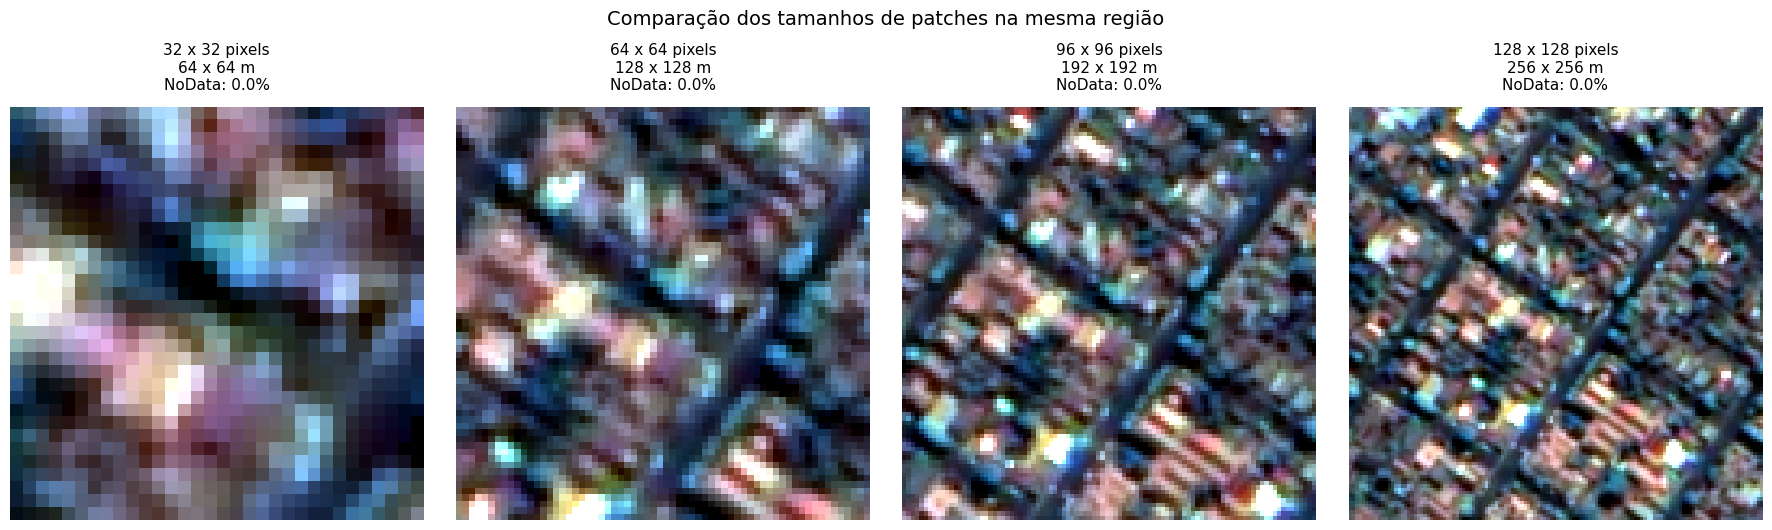

In [ ]:
# Etapa 14 — Comparação visual dos tamanhos de patches

import numpy as np
import matplotlib.pyplot as plt
from rasterio.windows import Window

# Identificar pixels válidos da imagem
mascara_valida = np.any(imagem != src.nodata, axis=0)

# Encontrar a região que contém dados válidos
linhas_validas, colunas_validas = np.where(mascara_valida)

# Escolher o centro da região válida
linha_central = int((linhas_validas.min() + linhas_validas.max()) / 2)
coluna_central = int((colunas_validas.min() + colunas_validas.max()) / 2)

print("===== COMPARAÇÃO VISUAL DOS PATCHES =====")
print("Linha central:", linha_central)
print("Coluna central:", coluna_central)

# Criar a figura
fig, axes = plt.subplots(
    1,
    len(configuracoes),
    figsize=(18, 5)
)

# Comparar os quatro tamanhos
for i, (tamanho_patch, stride) in enumerate(configuracoes):

    # Calcular a posição inicial do recorte
    linha = linha_central - tamanho_patch // 2
    coluna = coluna_central - tamanho_patch // 2

    # Garantir que o recorte permaneça dentro da imagem
    linha = max(0, min(linha, src.height - tamanho_patch))
    coluna = max(0, min(coluna, src.width - tamanho_patch))

    # Criar a janela de leitura
    janela = Window(
        coluna,
        linha,
        tamanho_patch,
        tamanho_patch
    )

    # Ler o patch diretamente da imagem original
    patch = src.read(window=janela)

    # Calcular o percentual de NoData
    mascara_nodata = np.all(
        patch == src.nodata,
        axis=0
    )

    percentual_nodata = mascara_nodata.mean() * 100

    # Composição RGB
    vermelho = ajustar_visualizacao(patch[2])
    verde = ajustar_visualizacao(patch[1])
    azul = ajustar_visualizacao(patch[0])

    patch_rgb = np.dstack(
        (vermelho, verde, azul)
    )

    # Dimensão no terreno
    dimensao_m = tamanho_patch * src.res[0]

    # Exibir o patch
    axes[i].imshow(patch_rgb)

    axes[i].set_title(
        f"{tamanho_patch} x {tamanho_patch} pixels\n"
        f"{dimensao_m:.0f} x {dimensao_m:.0f} m\n"
        f"NoData: {percentual_nodata:.1f}%",
        fontsize=11,
        pad=12
    )

    axes[i].axis("off")

# Título principal
fig.suptitle(
    "Comparação dos tamanhos de patches na mesma região",
    fontsize=14,
    y=1.05
)

plt.tight_layout()
plt.show()

# Parte 3 — Anotação no CVAT e extração de amostras

### 15 — Preparação de patches RGB para o CVAT

===== PREPARAÇÃO DOS PATCHES PARA O CVAT =====
Arquivo salvo: patch_64x64_L64_C96.png
Arquivo salvo: patch_64x64_L192_C64.png
Arquivo salvo: patch_64x64_L256_C160.png
Arquivo salvo: patch_64x64_L320_C320.png
Arquivo salvo: patch_64x64_L512_C224.png


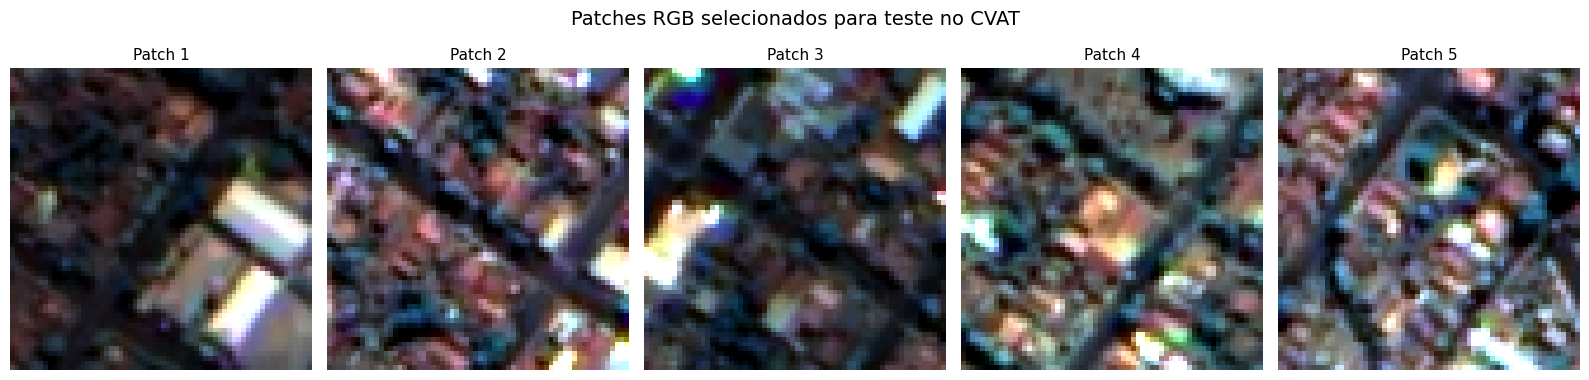


Total de PNGs gerados: 5
Pasta de destino: /content/drive/MyDrive/CBERS4A/CVAT_teste


In [ ]:
# Etapa 15 — Preparação de patches RGB para o CVAT

import os
import numpy as np
import matplotlib.pyplot as plt

# Pasta de destino no Google Drive
pasta_cvat = "/content/drive/MyDrive/CBERS4A/CVAT_teste"

os.makedirs(pasta_cvat, exist_ok=True)

# Selecionar apenas patches de 64 x 64 sem NoData
candidatos = [
    item for item in patches_sem_nodata
    if item["tamanho_patch"] == 64
]

# Selecionar 5 patches distribuídos pela lista
indices = np.linspace(
    0,
    len(candidatos) - 1,
    5,
    dtype=int
)

patches_teste = [candidatos[i] for i in indices]

print("===== PREPARAÇÃO DOS PATCHES PARA O CVAT =====")

# Criar figura para visualizar os patches
fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for i, item in enumerate(patches_teste):

    patch = item["dados"]

    # Composição RGB
    vermelho = ajustar_visualizacao(patch[2])
    verde = ajustar_visualizacao(patch[1])
    azul = ajustar_visualizacao(patch[0])

    patch_rgb = np.dstack(
        (vermelho, verde, azul)
    )

    # Nome correspondente ao GeoTIFF original
    nome_base = (
        f"patch_64x64"
        f"_L{item['linha']}_C{item['coluna']}"
    )

    nome_png = nome_base + ".png"

    caminho_png = os.path.join(
        pasta_cvat,
        nome_png
    )

    # Salvar PNG RGB
    plt.imsave(caminho_png, patch_rgb)

    # Mostrar na tela
    axes[i].imshow(patch_rgb)
    axes[i].set_title(f"Patch {i+1}", fontsize=11)
    axes[i].axis("off")

    print("Arquivo salvo:", nome_png)

plt.suptitle(
    "Patches RGB selecionados para teste no CVAT",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("\nTotal de PNGs gerados:", len(patches_teste))
print("Pasta de destino:", pasta_cvat)

### 16 — Importação das anotações do CVAT no Google Colab

In [ ]:
# Localização das anotações exportadas do CVAT

import os

pasta_anotacoes = "/content/drive/MyDrive/CBERS4A/CVAT_anotacoes"

arquivos = os.listdir(pasta_anotacoes)

print("===== ARQUIVOS EXPORTADOS DO CVAT =====")

for arquivo in arquivos:
    print(arquivo)

===== ARQUIVOS EXPORTADOS DO CVAT =====
anotacoes_CBERS4A_2_classes_teste.zip


### 17 — Leitura das anotações exportadas do CVAT

In [ ]:
# Leitura das anotações exportadas do CVAT

import os
import zipfile

# Pasta onde o ZIP foi salvo no Google Drive
pasta_anotacoes = "/content/drive/MyDrive/CBERS4A/CVAT_anotacoes"

# Localizar os arquivos ZIP
arquivos_zip = [
    arquivo for arquivo in os.listdir(pasta_anotacoes)
    if arquivo.lower().endswith(".zip")
]

print("===== ARQUIVOS ZIP ENCONTRADOS =====")

for arquivo in arquivos_zip:
    print(arquivo)

if not arquivos_zip:
    raise FileNotFoundError(
        "Nenhum arquivo ZIP foi encontrado na pasta."
    )

# Utilizar o primeiro ZIP encontrado
caminho_zip = os.path.join(
    pasta_anotacoes,
    arquivos_zip[0]
)

# Verificar o conteúdo do ZIP
with zipfile.ZipFile(caminho_zip, "r") as zip_ref:

    arquivos_internos = zip_ref.namelist()

    print("\n===== CONTEÚDO DO ZIP =====")

    for arquivo in arquivos_internos:
        print(arquivo)

    # Procurar o XML de anotações
    arquivos_xml = [
        arquivo for arquivo in arquivos_internos
        if arquivo.endswith("annotations.xml")
    ]

    if arquivos_xml:
        print("\nArquivo de anotações encontrado:")
        print(arquivos_xml[0])
    else:
        print("\nATENÇÃO: annotations.xml não encontrado.")

===== ARQUIVOS ZIP ENCONTRADOS =====
anotacoes_CBERS4A_2_classes_teste.zip

===== CONTEÚDO DO ZIP =====
annotations.xml

Arquivo de anotações encontrado:
annotations.xml


### 18 — Verificação das anotações do CVAT

In [ ]:
# Etapa 19 — Verificação das anotações do CVAT

import xml.etree.ElementTree as ET
from collections import Counter

# Ler o XML diretamente do ZIP
with zipfile.ZipFile(caminho_zip, "r") as zip_ref:
    with zip_ref.open("annotations.xml") as arquivo:
        arvore = ET.parse(arquivo)

raiz = arvore.getroot()

# Localizar as imagens
imagens_xml = raiz.findall("image")

print("===== ANOTAÇÕES EXPORTADAS DO CVAT =====")
print("Quantidade de imagens:", len(imagens_xml))

# Contadores
total_poligonos = 0
contagem_classes = Counter()

# Percorrer as imagens anotadas
for imagem_xml in imagens_xml:

    nome_imagem = imagem_xml.get("name")
    largura = imagem_xml.get("width")
    altura = imagem_xml.get("height")

    poligonos = imagem_xml.findall("polygon")

    print(f"\nImagem: {nome_imagem}")
    print(f"Dimensões: {largura} x {altura} pixels")
    print("Quantidade de polígonos:", len(poligonos))

    for poligono in poligonos:

        classe = poligono.get("label")
        pontos = poligono.get("points")

        contagem_classes[classe] += 1
        total_poligonos += 1

        quantidade_pontos = len(pontos.split(";"))

        print(
            f"  Classe: {classe} | "
            f"Pontos do polígono: {quantidade_pontos}"
        )

# Resumo geral
print("\n===== RESUMO DAS ANOTAÇÕES =====")
print("Total de imagens:", len(imagens_xml))
print("Total de polígonos:", total_poligonos)

print("\nPolígonos por classe:")

for classe, quantidade in contagem_classes.items():
    print(f"{classe}: {quantidade}")

===== ANOTAÇÕES EXPORTADAS DO CVAT =====
Quantidade de imagens: 5

Imagem: patch_64x64_L192_C64.png
Dimensões: 64 x 64 pixels
Quantidade de polígonos: 8
  Classe: Outros | Pontos do polígono: 4
  Classe: Outros | Pontos do polígono: 4
  Classe: Outros | Pontos do polígono: 4
  Classe: Vegetação arbórea | Pontos do polígono: 4
  Classe: Vegetação arbórea | Pontos do polígono: 4
  Classe: Vegetação arbórea | Pontos do polígono: 4
  Classe: Vegetação arbórea | Pontos do polígono: 7
  Classe: Outros | Pontos do polígono: 4

Imagem: patch_64x64_L256_C160.png
Dimensões: 64 x 64 pixels
Quantidade de polígonos: 6
  Classe: Outros | Pontos do polígono: 4
  Classe: Vegetação arbórea | Pontos do polígono: 5
  Classe: Vegetação arbórea | Pontos do polígono: 4
  Classe: Outros | Pontos do polígono: 5
  Classe: Outros | Pontos do polígono: 4
  Classe: Outros | Pontos do polígono: 5

Imagem: patch_64x64_L320_C320.png
Dimensões: 64 x 64 pixels
Quantidade de polígonos: 7
  Classe: Vegetação arbórea | P

19- Visualização dos polígonos no Colab

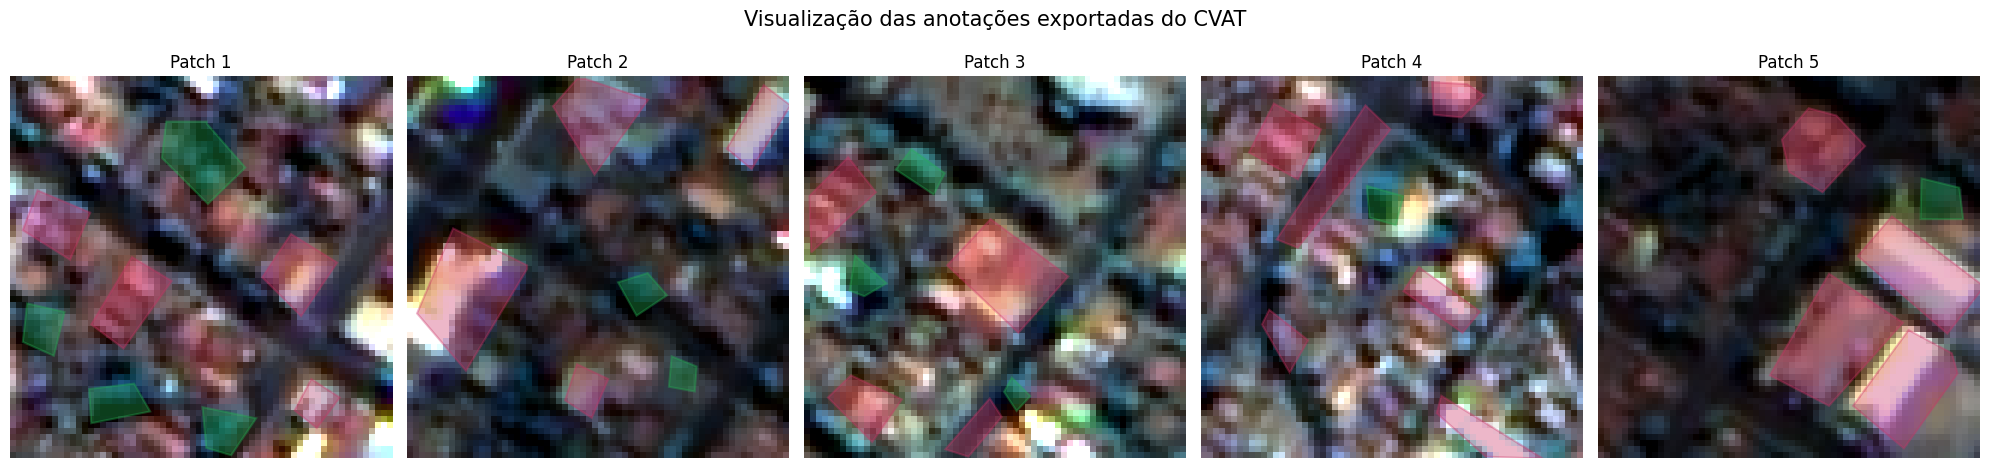

In [ ]:
# Visualização dos polígonos do CVAT

import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from PIL import Image
import numpy as np
import os

# Pasta das imagens PNG utilizadas no CVAT
pasta_imagens = "/content/drive/MyDrive/CBERS4A/CVAT_teste"

# Cores das classes
cores_classes = {
    "Outros": "#cc3366",
    "Vegetação arbórea": "#24b353"
}

# Criar figura para as cinco imagens
fig, eixos = plt.subplots(1, 5, figsize=(20, 5))

for i, imagem_xml in enumerate(imagens_xml):

    nome_imagem = imagem_xml.get("name")
    caminho_imagem = os.path.join(
        pasta_imagens,
        os.path.basename(nome_imagem)
    )

    # Abrir imagem original
    imagem = np.array(Image.open(caminho_imagem))

    ax = eixos[i]
    ax.imshow(imagem)

    # Recuperar polígonos da imagem
    poligonos = imagem_xml.findall("polygon")

    for poligono in poligonos:

        classe = poligono.get("label")
        pontos_texto = poligono.get("points")

        # Converter coordenadas do XML
        pontos = np.array([
            [float(valor) for valor in ponto.split(",")]
            for ponto in pontos_texto.split(";")
        ])

        # Desenhar polígono sobre a imagem
        desenho = Polygon(
            pontos,
            closed=True,
            fill=True,
            facecolor=cores_classes[classe],
            edgecolor=cores_classes[classe],
            alpha=0.35,
            linewidth=1.5
        )

        ax.add_patch(desenho)

    ax.set_title(f"Patch {i+1}", fontsize=12)
    ax.axis("off")

plt.suptitle(
    "Visualização das anotações exportadas do CVAT",
    fontsize=15
)

plt.tight_layout()
plt.show()

### 20- Conversão dos polígonos em máscaras de classificação

In [ ]:
# Conversão dos polígonos em máscaras raster

import os
import numpy as np
from PIL import Image, ImageDraw

# Classes
codigos_classes = {
    "Outros": 0,
    "Vegetação arbórea": 1
}

# Valor para pixels não anotados
valor_nao_anotado = 255

# Pasta de saída
pasta_mascaras = "/content/drive/MyDrive/CBERS4A/CVAT_mascaras"

os.makedirs(pasta_mascaras, exist_ok=True)

print("===== GERAÇÃO DAS MÁSCARAS =====")

for imagem_xml in imagens_xml:

    nome_imagem = os.path.basename(imagem_xml.get("name"))

    largura = int(imagem_xml.get("width"))
    altura = int(imagem_xml.get("height"))

    # Criar máscara inicialmente sem anotações
    mascara = Image.new(
        "L",
        (largura, altura),
        color=valor_nao_anotado
    )

    desenho = ImageDraw.Draw(mascara)

    # Percorrer os polígonos
    for poligono in imagem_xml.findall("polygon"):

        classe = poligono.get("label")
        pontos_texto = poligono.get("points")

        pontos = [
            tuple(float(valor) for valor in ponto.split(","))
            for ponto in pontos_texto.split(";")
        ]

        # Preencher a região com o código da classe
        desenho.polygon(
            pontos,
            fill=codigos_classes[classe]
        )

    # Converter para array
    mascara_array = np.array(mascara)

    # Nome do arquivo de saída
    nome_mascara = nome_imagem.replace(
        ".png", "_mascara.png"
    )

    caminho_saida = os.path.join(
        pasta_mascaras,
        nome_mascara
    )

    # Salvar máscara
    Image.fromarray(mascara_array).save(caminho_saida)

    # Conferir valores encontrados
    valores, quantidades = np.unique(
        mascara_array,
        return_counts=True
    )

    print(f"\nImagem: {nome_imagem}")
    print(f"Máscara salva: {nome_mascara}")

    for valor, quantidade in zip(valores, quantidades):
        print(f"  Valor {valor}: {quantidade} pixels")

print("\nMáscaras geradas com sucesso!")

===== GERAÇÃO DAS MÁSCARAS =====

Imagem: patch_64x64_L192_C64.png
Máscara salva: patch_64x64_L192_C64_mascara.png
  Valor 0: 345 pixels
  Valor 1: 291 pixels
  Valor 255: 3460 pixels

Imagem: patch_64x64_L256_C160.png
Máscara salva: patch_64x64_L256_C160_mascara.png
  Valor 0: 516 pixels
  Valor 1: 68 pixels
  Valor 255: 3512 pixels

Imagem: patch_64x64_L320_C320.png
Máscara salva: patch_64x64_L320_C320_mascara.png
  Valor 0: 431 pixels
  Valor 1: 86 pixels
  Valor 255: 3579 pixels

Imagem: patch_64x64_L512_C224.png
Máscara salva: patch_64x64_L512_C224_mascara.png
  Valor 0: 479 pixels
  Valor 1: 39 pixels
  Valor 255: 3578 pixels

Imagem: patch_64x64_L64_C96.png
Máscara salva: patch_64x64_L64_C96_mascara.png
  Valor 0: 778 pixels
  Valor 1: 53 pixels
  Valor 255: 3265 pixels

Máscaras geradas com sucesso!


### 21- Visualização das imagens e suas máscaras

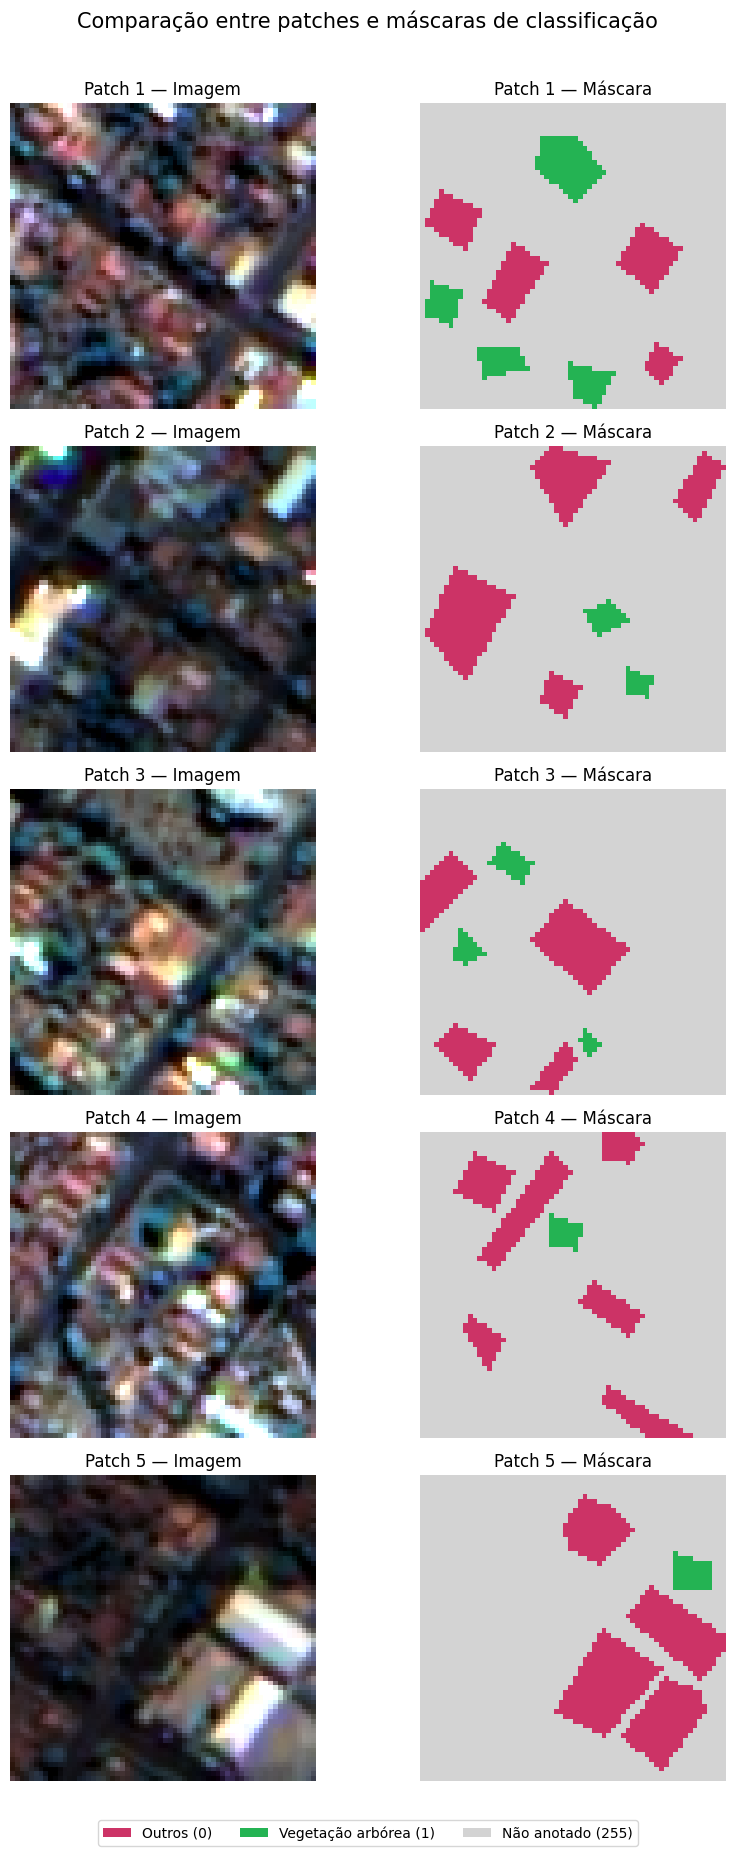

In [ ]:
#  Visualização das imagens e máscaras

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from PIL import Image
import numpy as np
import os
from matplotlib.patches import Patch

# Cores: Outros, Vegetação arbórea e Não anotado
cores = ["#cc3366", "#24b353", "#D3D3D3"]

mapa_cores = ListedColormap(cores)
normalizacao = BoundaryNorm(
    [-0.5, 0.5, 1.5, 2.5],
    mapa_cores.N
)

fig, eixos = plt.subplots(
    5, 2,
    figsize=(9, 19)
)

for i, imagem_xml in enumerate(imagens_xml):

    nome_imagem = os.path.basename(
        imagem_xml.get("name")
    )

    # Caminho da imagem original
    caminho_imagem = os.path.join(
        pasta_imagens,
        nome_imagem
    )

    # Caminho da máscara
    nome_mascara = nome_imagem.replace(
        ".png", "_mascara.png"
    )

    caminho_mascara = os.path.join(
        pasta_mascaras,
        nome_mascara
    )

    # Carregar imagem e máscara
    imagem = np.array(Image.open(caminho_imagem))
    mascara = np.array(Image.open(caminho_mascara))

    # Adaptar valores para visualização
    mascara_visual = mascara.copy()
    mascara_visual[mascara_visual == 255] = 2

    # Imagem original
    eixos[i, 0].imshow(imagem)
    eixos[i, 0].set_title(f"Patch {i+1} — Imagem")
    eixos[i, 0].axis("off")

    # Máscara
    eixos[i, 1].imshow(
        mascara_visual,
        cmap=mapa_cores,
        norm=normalizacao,
        interpolation="nearest"
    )

    eixos[i, 1].set_title(f"Patch {i+1} — Máscara")
    eixos[i, 1].axis("off")

# Legenda
legenda = [
    Patch(facecolor="#cc3366", label="Outros (0)"),
    Patch(facecolor="#24b353", label="Vegetação arbórea (1)"),
    Patch(facecolor="#D3D3D3", label="Não anotado (255)")
]

fig.legend(
    handles=legenda,
    loc="lower center",
    ncol=3,
    bbox_to_anchor=(0.5, 0.01)
)

plt.suptitle(
    "Comparação entre patches e máscaras de classificação",
    fontsize=15
)

plt.tight_layout(rect=[0, 0.04, 1, 0.97])
plt.show()

### 22- Associação das máscaras aos patches GeoTIFF

In [ ]:
# Associação das máscaras aos patches GeoTIFF

import os
import rasterio
import numpy as np
from PIL import Image

pasta_geotiff = (
    "/content/drive/MyDrive/CBERS4A/"
    "patches_validos/64x64"
)

print("===== VERIFICAÇÃO DOS PARES =====")

pares_validos = []

for imagem_xml in imagens_xml:

    nome_png = os.path.basename(imagem_xml.get("name"))

    nome_tif = os.path.splitext(nome_png)[0] + ".tif"

    nome_mascara = (
        os.path.splitext(nome_png)[0] + "_mascara.png"
    )

    caminho_tif = os.path.join(pasta_geotiff, nome_tif)
    caminho_mascara = os.path.join(
        pasta_mascaras, nome_mascara
    )

    if not os.path.exists(caminho_tif):
        print(f"\nGeoTIFF não encontrado: {nome_tif}")
        continue

    if not os.path.exists(caminho_mascara):
        print(f"\nMáscara não encontrada: {nome_mascara}")
        continue

    with rasterio.open(caminho_tif) as src:
        bandas = src.count
        altura = src.height
        largura = src.width
        sistema_referencia = src.crs

    mascara = np.array(Image.open(caminho_mascara))

    dimensoes_compativeis = (
        mascara.shape == (altura, largura)
    )

    print(f"\nPatch: {nome_tif}")
    print(f"Bandas espectrais: {bandas}")
    print(f"Dimensões GeoTIFF: {altura} x {largura}")
    print(f"Dimensões máscara: {mascara.shape}")
    print(f"Sistema de referência: {sistema_referencia}")
    print(f"Dimensões compatíveis: {dimensoes_compativeis}")

    if dimensoes_compativeis and bandas == 4:
        pares_validos.append({
            "geotiff": caminho_tif,
            "mascara": caminho_mascara
        })

print("\n===== RESUMO =====")
print("Pares válidos encontrados:", len(pares_validos))
print("Total esperado:", len(imagens_xml))

===== VERIFICAÇÃO DOS PARES =====

Patch: patch_64x64_L192_C64.tif
Bandas espectrais: 4
Dimensões GeoTIFF: 64 x 64
Dimensões máscara: (64, 64)
Sistema de referência: EPSG:32722
Dimensões compatíveis: True

Patch: patch_64x64_L256_C160.tif
Bandas espectrais: 4
Dimensões GeoTIFF: 64 x 64
Dimensões máscara: (64, 64)
Sistema de referência: EPSG:32722
Dimensões compatíveis: True

Patch: patch_64x64_L320_C320.tif
Bandas espectrais: 4
Dimensões GeoTIFF: 64 x 64
Dimensões máscara: (64, 64)
Sistema de referência: EPSG:32722
Dimensões compatíveis: True

Patch: patch_64x64_L512_C224.tif
Bandas espectrais: 4
Dimensões GeoTIFF: 64 x 64
Dimensões máscara: (64, 64)
Sistema de referência: EPSG:32722
Dimensões compatíveis: True

Patch: patch_64x64_L64_C96.tif
Bandas espectrais: 4
Dimensões GeoTIFF: 64 x 64
Dimensões máscara: (64, 64)
Sistema de referência: EPSG:32722
Dimensões compatíveis: True

===== RESUMO =====
Pares válidos encontrados: 5
Total esperado: 5


### Etapa 24 - Conversão do XML do CVAT para Shapefile

In [ ]:
# Conversão do XML do CVAT para Shapefile

import os
import zipfile
import xml.etree.ElementTree as ET
import geopandas as gpd
import rasterio

from shapely.geometry import Polygon

# Caminhos
pasta_cvat = "/content/drive/MyDrive/CBERS4A/CVAT_anotacoes"

pasta_geotiff = (
    "/content/drive/MyDrive/CBERS4A/"
    "patches_validos/64x64"
)

pasta_saida = (
    "/content/drive/MyDrive/CBERS4A/"
    "CVAT_shapefile"
)

os.makedirs(pasta_saida, exist_ok=True)

# Localizar arquivo ZIP do CVAT
arquivos_zip = [
    arq for arq in os.listdir(pasta_cvat)
    if arq.lower().endswith(".zip")
]

if not arquivos_zip:
    raise FileNotFoundError("Nenhum ZIP encontrado.")

caminho_zip = os.path.join(pasta_cvat, arquivos_zip[0])

# Ler o XML
with zipfile.ZipFile(caminho_zip, "r") as z:
    nomes_xml = [
        nome for nome in z.namelist()
        if os.path.basename(nome) == "annotations.xml"
    ]

    if not nomes_xml:
        raise FileNotFoundError("annotations.xml não encontrado.")

    raiz = ET.fromstring(z.read(nomes_xml[0]))

# Armazenar polígonos
registros = []
crs_saida = None

for imagem_xml in raiz.findall("image"):

    nome_png = os.path.basename(imagem_xml.get("name"))

    nome_tif = os.path.splitext(nome_png)[0] + ".tif"

    caminho_tif = os.path.join(
        pasta_geotiff,
        nome_tif
    )

    if not os.path.exists(caminho_tif):
        raise FileNotFoundError(
            f"GeoTIFF não encontrado: {nome_tif}"
        )

    with rasterio.open(caminho_tif) as src:

        transformacao = src.transform
        crs_atual = src.crs

        if crs_atual is None:
            raise ValueError(f"GeoTIFF sem CRS: {nome_tif}")

        if crs_saida is None:
            crs_saida = crs_atual
        elif crs_atual != crs_saida:
            raise ValueError(
                "Os GeoTIFFs possuem sistemas de referência diferentes."
            )

        # Percorrer os polígonos da imagem
        for poligono_xml in imagem_xml.findall("polygon"):

            classe = poligono_xml.get("label")
            pontos_texto = poligono_xml.get("points")

            pontos_geo = []

            for ponto in pontos_texto.split(";"):

                x_pixel, y_pixel = map(
                    float,
                    ponto.split(",")
                )

                # Converter pixels para coordenadas UTM
                x_geo, y_geo = transformacao * (
                    x_pixel,
                    y_pixel
                )

                pontos_geo.append((x_geo, y_geo))

            # Criar geometria vetorial
            geometria = Polygon(pontos_geo)

            if geometria.is_empty or not geometria.is_valid:
                raise ValueError(
                    f"Polígono inválido na imagem {nome_png}"
                )

            registros.append({
                "classe": classe,
                "imagem": nome_tif,
                "geometry": geometria
            })

# Criar GeoDataFrame
gdf = gpd.GeoDataFrame(
    registros,
    geometry="geometry",
    crs=crs_saida
)

# Identificar cada polígono
gdf.insert(0, "id", range(1, len(gdf) + 1))

# Calcular a área de cada polígono (m² em UTM)
gdf["area_m2"] = gdf.geometry.area

# Salvar como Shapefile
caminho_shp = os.path.join(
    pasta_saida,
    "poligonos_CVAT_CBERS4A.shp"
)

gdf.to_file(
    caminho_shp,
    driver="ESRI Shapefile",
    encoding="UTF-8"
)

print("===== CONVERSÃO CONCLUÍDA =====")
print("Shapefile salvo em:", caminho_shp)
print("Quantidade de polígonos:", len(gdf))
print("Sistema de referência:", gdf.crs)

print("\nPolígonos por classe:")
print(gdf["classe"].value_counts())

print("\nÁrea média dos polígonos por classe (m²):")
print(gdf.groupby("classe")["area_m2"].mean().round(2))

===== CONVERSÃO CONCLUÍDA =====
Shapefile salvo em: /content/drive/MyDrive/CBERS4A/CVAT_shapefile/poligonos_CVAT_CBERS4A.shp
Quantidade de polígonos: 33
Sistema de referência: PROJCS["WGS 84 / UTM zone 22S",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-51],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",10000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32722"]]

Polígonos por classe:
classe
Outros               22
Vegetação arbórea    11
Name: count, dtype: int64

Área média dos polígonos por classe (m²):
classe
Outros               414.07
Vegetação arbórea    157.97
Name: ar

### Etapa 25 - Separação do XML por Classe

In [ ]:
# Separação do XML por classe

import os
import copy
import xml.etree.ElementTree as ET

pasta_saida_xml = (
    "/content/drive/MyDrive/CBERS4A/CVAT_XML_por_classe"
)

os.makedirs(pasta_saida_xml, exist_ok=True)

classes = {
    "Vegetação arbórea": "Vegetacao_arborea.xml",
    "Outros": "Outros.xml"
}

for classe, nome_arquivo in classes.items():

    # Copiar o XML original
    raiz_classe = copy.deepcopy(raiz)

    total = 0

    for imagem in raiz_classe.findall("image"):

        for poligono in list(imagem.findall("polygon")):

            if poligono.get("label") != classe:
                imagem.remove(poligono)
            else:
                total += 1

    caminho_saida = os.path.join(
        pasta_saida_xml,
        nome_arquivo
    )

    arvore_saida = ET.ElementTree(raiz_classe)

    arvore_saida.write(
        caminho_saida,
        encoding="utf-8",
        xml_declaration=True
    )

    print(f"{classe}: {total} polígonos")
    print(f"Arquivo: {caminho_saida}\n")

Vegetação arbórea: 11 polígonos
Arquivo: /content/drive/MyDrive/CBERS4A/CVAT_XML_por_classe/Vegetacao_arborea.xml

Outros: 22 polígonos
Arquivo: /content/drive/MyDrive/CBERS4A/CVAT_XML_por_classe/Outros.xml



### Etapa 26 - Extração de cada polígono em GeoTIFF de 4 bandas

In [ ]:
# Extração de cada polígono em GeoTIFF de 4 bandas

import os
import zipfile
import xml.etree.ElementTree as ET
import numpy as np
import rasterio

from rasterio.features import geometry_mask
from rasterio.windows import Window, transform as window_transform
from shapely.geometry import Polygon, mapping

# Pasta com o ZIP exportado do CVAT
pasta_cvat = "/content/drive/MyDrive/CBERS4A/CVAT_anotacoes"

# Pasta com os GeoTIFFs originais
pasta_geotiff = (
    "/content/drive/MyDrive/CBERS4A/patches_validos/64x64"
)

# Pasta de saída dos TIFFs individuais
pasta_saida = (
    "/content/drive/MyDrive/CBERS4A/CVAT_TIFF_individuais"
)

# Pastas por classe
classes = {
    "Vegetação arbórea": "Vegetacao_arborea",
    "Outros": "Outros"
}

for nome_pasta in classes.values():
    os.makedirs(
        os.path.join(pasta_saida, nome_pasta),
        exist_ok=True
    )

# Localizar o ZIP
arquivos_zip = [
    arquivo for arquivo in os.listdir(pasta_cvat)
    if arquivo.lower().endswith(".zip")
]

if not arquivos_zip:
    raise FileNotFoundError("ZIP do CVAT não encontrado.")

caminho_zip = os.path.join(pasta_cvat, arquivos_zip[0])

# Ler as anotações XML
with zipfile.ZipFile(caminho_zip, "r") as z:

    arquivos_xml = [
        nome for nome in z.namelist()
        if os.path.basename(nome) == "annotations.xml"
    ]

    if not arquivos_xml:
        raise FileNotFoundError("annotations.xml não encontrado.")

    raiz = ET.fromstring(z.read(arquivos_xml[0]))

# Contar os arquivos de cada classe
contadores = {
    "Vegetação arbórea": 0,
    "Outros": 0
}

print("===== EXTRAÇÃO DAS AMOSTRAS TIFF =====")

for imagem_xml in raiz.findall("image"):

    nome_png = os.path.basename(imagem_xml.get("name"))
    nome_base = os.path.splitext(nome_png)[0]

    caminho_tif = os.path.join(
        pasta_geotiff,
        nome_base + ".tif"
    )

    if not os.path.exists(caminho_tif):
        raise FileNotFoundError(
            f"GeoTIFF não encontrado: {caminho_tif}"
        )

    with rasterio.open(caminho_tif) as src:

        if src.count != 4:
            raise ValueError(
                f"O arquivo {nome_base} não possui 4 bandas."
            )

        for poligono_xml in imagem_xml.findall("polygon"):

            classe = poligono_xml.get("label")

            if classe not in classes:
                raise ValueError(f"Classe desconhecida: {classe}")

            # Coordenadas do polígono na imagem
            pontos = [
                tuple(map(float, ponto.split(",")))
                for ponto in poligono_xml.get("points").split(";")
            ]

            # Converter coordenadas de pixels para UTM
            pontos_geo = [
                src.transform * (x, y)
                for x, y in pontos
            ]

            geometria = Polygon(pontos_geo)

            if not geometria.is_valid or geometria.is_empty:
                raise ValueError(
                    f"Polígono inválido em {nome_base}"
                )

            # Identificar os pixels pertencentes ao polígono
            mascara = geometry_mask(
                [mapping(geometria)],
                out_shape=(src.height, src.width),
                transform=src.transform,
                invert=True
            )

            # Localizar a área ocupada pelo polígono
            linhas, colunas = np.where(mascara)

            if len(linhas) == 0:
                raise ValueError(
                    f"Polígono sem pixels selecionados: {nome_base}"
                )

            linha_min = int(linhas.min())
            linha_max = int(linhas.max()) + 1
            coluna_min = int(colunas.min())
            coluna_max = int(colunas.max()) + 1

            # Janela de recorte
            janela = Window(
                coluna_min,
                linha_min,
                coluna_max - coluna_min,
                linha_max - linha_min
            )

            # Ler as quatro bandas originais
            recorte = src.read(window=janela)

            # Máscara correspondente ao recorte
            mascara_recorte = mascara[
                linha_min:linha_max,
                coluna_min:coluna_max
            ]

            # Definir NoData fora do polígono
            nodata_saida = src.nodata

            if nodata_saida is None:
                nodata_saida = 0

            recorte[:, ~mascara_recorte] = nodata_saida

            # Atualizar informações geográficas
            perfil = src.profile.copy()

            perfil.update(
                height=recorte.shape[1],
                width=recorte.shape[2],
                transform=window_transform(janela, src.transform),
                count=4,
                nodata=nodata_saida
            )

            # Nome do arquivo individual
            contadores[classe] += 1
            numero = contadores[classe]

            nome_saida = (
                f"amostra_{numero:03d}_{nome_base}.tif"
            )

            caminho_saida = os.path.join(
                pasta_saida,
                classes[classe],
                nome_saida
            )

            # Salvar GeoTIFF
            with rasterio.open(
                caminho_saida,
                "w",
                **perfil
            ) as dst:
                dst.write(recorte)

            print(
                f"{classe} | {nome_saida} | "
                f"{recorte.shape[2]} x {recorte.shape[1]} pixels"
            )

print("\n===== RESUMO =====")

for classe, quantidade in contadores.items():
    print(f"{classe}: {quantidade} arquivos TIFF")

print("\nTotal:", sum(contadores.values()))
print("Arquivos salvos em:", pasta_saida)

===== EXTRAÇÃO DAS AMOSTRAS TIFF =====
Outros | amostra_001_patch_64x64_L192_C64.tif | 8 x 7 pixels
Outros | amostra_002_patch_64x64_L192_C64.tif | 12 x 13 pixels


Outros | amostra_003_patch_64x64_L192_C64.tif | 13 x 15 pixels
Vegetação arbórea | amostra_001_patch_64x64_L192_C64.tif | 8 x 8 pixels
Vegetação arbórea | amostra_002_patch_64x64_L192_C64.tif | 7 x 8 pixels
Vegetação arbórea | amostra_003_patch_64x64_L192_C64.tif | 10 x 7 pixels


Vegetação arbórea | amostra_004_patch_64x64_L192_C64.tif | 14 x 14 pixels
Outros | amostra_004_patch_64x64_L192_C64.tif | 11 x 11 pixels
Outros | amostra_005_patch_64x64_L256_C160.tif | 11 x 14 pixels
Vegetação arbórea | amostra_005_patch_64x64_L256_C160.tif | 5 x 5 pixels


Vegetação arbórea | amostra_006_patch_64x64_L256_C160.tif | 8 x 6 pixels
Outros | amostra_006_patch_64x64_L256_C160.tif | 19 x 24 pixels
Outros | amostra_007_patch_64x64_L256_C160.tif | 7 x 9 pixels
Outros | amostra_008_patch_64x64_L256_C160.tif | 16 x 15 pixels


Vegetação arbórea | amostra_007_patch_64x64_L320_C320.tif | 6 x 6 pixels
Vegetação arbórea | amostra_008_patch_64x64_L320_C320.tif | 8 x 7 pixels
Outros | amostra_009_patch_64x64_L320_C320.tif | 19 x 18 pixels


Outros | amostra_010_patch_64x64_L320_C320.tif | 9 x 9 pixels
Outros | amostra_011_patch_64x64_L320_C320.tif | 12 x 10 pixels
Outros | amostra_012_patch_64x64_L320_C320.tif | 11 x 14 pixels
Vegetação arbórea | amostra_009_patch_64x64_L320_C320.tif | 4 x 5 pixels


Outros | amostra_013_patch_64x64_L512_C224.tif | 9 x 5 pixels
Outros | amostra_014_patch_64x64_L512_C224.tif | 13 x 10 pixels
Outros | amostra_015_patch_64x64_L512_C224.tif | 7 x 10 pixels
Outros | amostra_016_patch_64x64_L512_C224.tif | 19 x 23 pixels


Outros | amostra_017_patch_64x64_L512_C224.tif | 12 x 12 pixels
Outros | amostra_018_patch_64x64_L512_C224.tif | 18 x 10 pixels
Vegetação arbórea | amostra_010_patch_64x64_L512_C224.tif | 6 x 6 pixels
Outros | amostra_019_patch_64x64_L64_C96.tif | 21 x 19 pixels


Outros | amostra_020_patch_64x64_L64_C96.tif | 22 x 21 pixels
Outros | amostra_021_patch_64x64_L64_C96.tif | 18 x 20 pixels
Outros | amostra_022_patch_64x64_L64_C96.tif | 14 x 14 pixels
Vegetação arbórea | amostra_011_patch_64x64_L64_C96.tif | 7 x 6 pixels

===== RESUMO =====
Vegetação arbórea: 11 arquivos TIFF
Outros: 22 arquivos TIFF

Total: 33
Arquivos salvos em: /content/drive/MyDrive/CBERS4A/CVAT_TIFF_individuais
